In [4]:
print("This program run by Manthan Mishra")
print("Roll No.:- 36")

This program run by Manthan Mishra
Roll No.:- 36


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [6]:
df = pd.read_csv("housing.xls")

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

Dataset Shape: (20640, 10)

First 5 rows:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [7]:
print("Column Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())


Column Names:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'median_house_value', 'ocean_proximity']

Missing Values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


In [8]:
df = df.dropna()
X = df[
    [
        'longitude',
        'latitude',
        'housing_median_age',
        'total_rooms',
        'total_bedrooms',
        'population',
        'households',
        'median_income'
    ]
]
y = df['median_house_value']

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Features:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']

Target:
median_house_value


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16346, 8)
Testing data: (4087, 8)


In [10]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [11]:
model = LinearRegression()

model.fit(X_train_scaled, y_train)

print("Multiple Linear Regression model trained successfully.")

Multiple Linear Regression model trained successfully.


In [12]:
y_pred = model.predict(X_test_scaled)

print("First 10 Actual Values:")
print(y_test.values[:10])

print("\nFirst 10 Predicted Values:")
print(y_pred[:10])

First 10 Actual Values:
[245800. 137900. 218200. 220800. 170500.  75000. 269400. 228900. 500001.
  80800.]

First 10 Predicted Values:
[197058.03752153 157508.79088918 202099.26270387 173501.82273784
 213795.18417458 108004.59572814 284796.0440564  249128.96413381
 391338.74160318  49301.34850016]


In [13]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("----- Model Performance Evaluation -----")
print("Mean Squared Error (MSE)  :", round(mse, 4))
print("Root Mean Squared Error (RMSE):", round(rmse, 4))
print("R-squared Score (R²)      :", round(r2, 4))

----- Model Performance Evaluation -----
Mean Squared Error (MSE)  : 4921881237.6281
Root Mean Squared Error (RMSE): 70156.1205
R-squared Score (R²)      : 0.6401


In [14]:
print("Intercept (Beta 0):", model.intercept_)

for feature, coefficient in zip(X.columns, model.coef_):
    print(f"Coefficient for {feature} (Beta_i): {coefficient:.4f}")

Intercept (Beta 0): 206644.4000978828
Coefficient for longitude (Beta_i): -85341.7259
Coefficient for latitude (Beta_i): -90434.6708
Coefficient for housing_median_age (Beta_i): 14527.4114
Coefficient for total_rooms (Beta_i): -18174.2547
Coefficient for total_bedrooms (Beta_i): 48354.3074
Coefficient for population (Beta_i): -41513.2260
Coefficient for households (Beta_i): 15739.4966
Coefficient for median_income (Beta_i): 76467.2399


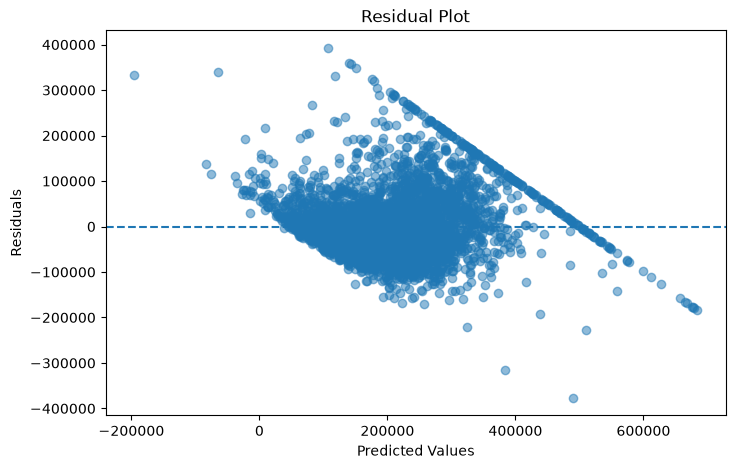

In [15]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.5)

plt.axhline(y=0, linestyle='--')

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

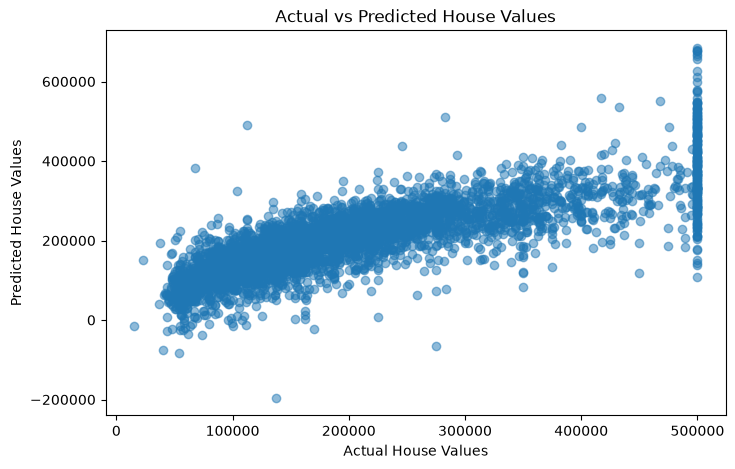

In [16]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual House Values")
plt.ylabel("Predicted House Values")
plt.title("Actual vs Predicted House Values")

plt.show()

In [17]:
print("========== FINAL RESULTS ==========")
print(f"Dataset Shape : {df.shape}")
print(f"Training Size : {len(X_train)}")
print(f"Testing Size  : {len(X_test)}")
print(f"MSE           : {mse:.4f}")
print(f"RMSE          : {rmse:.4f}")
print(f"R² Score      : {r2:.4f}")

========== FINAL RESULTS ==========
Dataset Shape : (20433, 10)
Training Size : 16346
Testing Size  : 4087
MSE           : 4921881237.6281
RMSE          : 70156.1205
R² Score      : 0.6401
